In [ ]:
import numpy as np
import urllib.request
import gzip

#Claude Generated code to import the damn dataset


def load_mnist():
    base_url = "https://storage.googleapis.com/cvdf-datasets/mnist/"
    files = {
        "train_images": "train-images-idx3-ubyte.gz",
        "train_labels": "train-labels-idx1-ubyte.gz",
        "test_images":  "t10k-images-idx3-ubyte.gz",
        "test_labels":  "t10k-labels-idx1-ubyte.gz",
    }

    data = {}
    for key, fname in files.items():
        urllib.request.urlretrieve(base_url + fname, fname)
        with gzip.open(fname, 'rb') as f:
            raw = np.frombuffer(f.read(), dtype=np.uint8)
            if "images" in key:
                data[key] = raw[16:].reshape(-1, 784)   # skip 16-byte header
            else:
                data[key] = raw[8:]                      # skip 8-byte header

    return data

data = load_mnist()
X_train = data["train_images"] / 255.0   # normalize to [0, 1]
y_train = data["train_labels"]
X_test  = data["test_images"]  / 255.0
y_test  = data["test_labels"]

X_train = np.transpose(X_train)
X_test = np.transpose(X_test)

def one_hot(y, classes=10):
    Y = np.zeros((classes, len(y)))
    Y[y, np.arange(len(y))] = 1
    return Y
Y_train = one_hot(y_train)   # (10, 60000)
Y_test = one_hot(y_test)     # (10, 10000)

In [ ]:
def cross_entropy_loss(Y, A):
    # Y is one-hot encoded (10, 60000)
    # A is softmax output  (10, 60000)
    return -np.mean(np.sum(Y * np.log(A + 1e-8), axis=0))

def softmax(Z):
    expZ = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return expZ / np.sum(expZ, axis=0, keepdims=True)

In [ ]:
#Initialization
W1 = np.random.randn(128, 784) * np.sqrt(2 / 784)
W2 = np.random.randn(10, 128)  * np.sqrt(2 / 128)
b1 = np.zeros((128,1))
b2 =np.zeros((10,1))

vW1 = np.zeros_like(W1)
vW2 = np.zeros_like(W2)
vb1 = np.zeros_like(b1)
vb2 = np.zeros_like(b2)

beta = 0.9  # standard value

lr = 0.01


In [ ]:

for iterations in range(500):

  Z1 = W1 @ X_train + b1
  A1 = np.maximum(Z1, 0)
  Z2 = W2 @ A1 + b2
  A2 = softmax(Z2)

  loss = cross_entropy_loss(Y_train, A2)
  losses.append(loss)
  print(iterations, loss)
  preds = np.argmax(A2, axis=0)
  acc = np.mean(preds == y_train)
  accuracies.append(acc)
  print(acc)

  dZ2 = A2 - Y_train                          # softmax + cross entropy, NOT the jacobian
  dA1 = W2.T @ dZ2                      # push gradient back through W2
  dZ1 = dA1 * (Z1 > 0)                  # ReLU mask
  dW1 = (dZ1 @ X_train.T) / 60000
  dW2 = dZ2 @ A1.T                      # (n2, m) @ (m, n1) = (n2, n1)
  db1 = np.sum(dZ1, axis=1, keepdims=True) / 60000
  db2 = np.sum(dZ2, axis=1, keepdims=True) / 60000

  vW1 = beta * vW1 + (1 - beta) * dW1
  vW2 = beta * vW2 + (1 - beta) * dW2
  vb1 = beta * vb1 + (1 - beta) * db1
  vb2 = beta * vb2 + (1 - beta) * db2

  W1 -= lr * vW1
  W2 -= lr * vW2
  b1 -= lr * vb1
  b2 -= lr * vb2






0 0.22250256571351082
0.9324333333333333
1 0.2223004200685631
0.9324833333333333
2 0.22209887146208968
0.93255
3 0.22189802543663706
0.9326333333333333
4 0.2216977500234726
0.9326833333333333
5 0.22149823382126893
0.9327166666666666
6 0.2212994606753214
0.9328333333333333
7 0.2211013084585892
0.9328333333333333
8 0.2209037849828119
0.9328666666666666
9 0.22070700567455273
0.93285
10 0.22051095212023022
0.9329
11 0.22031540915332193
0.9329166666666666
12 0.22012044721263782
0.93305
13 0.21992609186861117
0.9330833333333334
14 0.21973227447503205
0.9331333333333334
15 0.21953885200492929
0.9331833333333334
16 0.2193460335565826
0.9332666666666667
17 0.21915372335812244
0.9333
18 0.21896176640471515
0.9333833333333333
19 0.21877017925111703
0.9334166666666667
20 0.2185790927675734
0.93345
21 0.21838848332850358
0.9335
22 0.21819835717557148
0.93355
23 0.21800863874931753
0.9336333333333333
24 0.21781945933402258
0.9336833333333333
25 0.21763078091576804
0.9337666666666666
26 0.21744272071

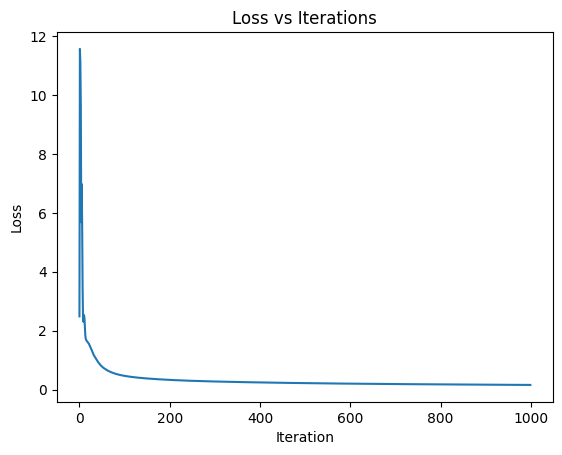

Test Accuracy: 94.77%


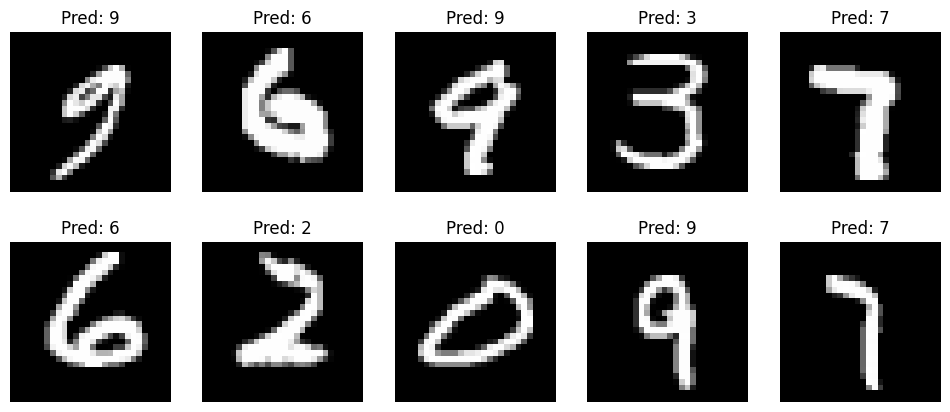

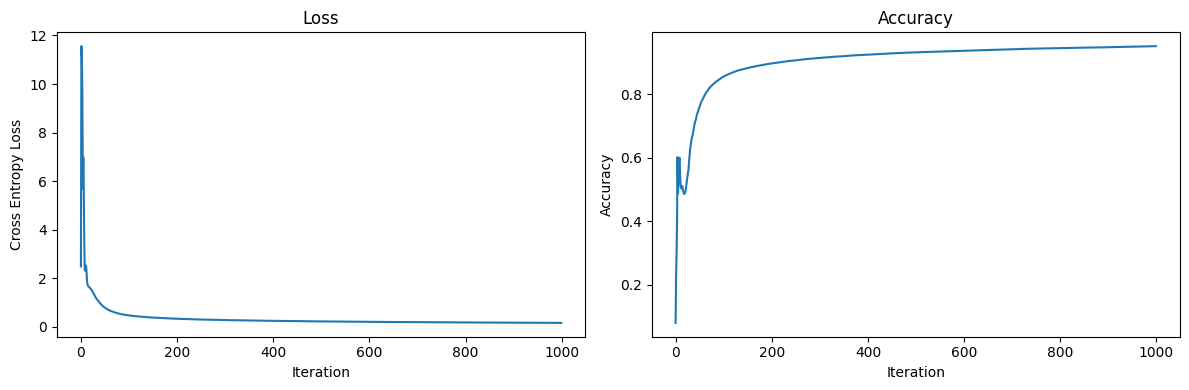

In [ ]:
import matplotlib.pyplot as plt

# Plot loss curve
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Loss vs Iterations")
plt.show()

# Evaluate on test set
Z1_test = W1 @ X_test + b1
A1_test = np.maximum(Z1_test, 0)
Z2_test = W2 @ A1_test + b2
A2_test = softmax(Z2_test)
predictions = np.argmax(A2_test, axis=0)
accuracy = np.mean(predictions == y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")

# Qualitative snapshots
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    idx = np.random.randint(0, X_test.shape[1])
    ax.imshow(X_test[:, idx].reshape(28, 28), cmap='gray')
    ax.set_title(f"Pred: {predictions[idx]}")
    ax.axis('off')
plt.show()

def plot_metrics(losses, accuracies):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(losses)
    ax1.set_title("Loss")
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("Cross Entropy Loss")

    ax2.plot(accuracies)
    ax2.set_title("Accuracy")
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("Accuracy")

    plt.tight_layout()
    plt.show()

plot_metrics(losses, accuracies)
